In [8]:
#Vérification des données d’entrée (Kaggle Input)
import os
import numpy as np
import pandas as pd

# Vérifier les fichiers disponibles
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames[:10]:  # afficher les 10 premiers
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/labels_with_split.csv
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/ee1f556064bfb97655bcfeaa48e5ca4b.csv
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/56cb6f7c292bdcc412c491f88954f19c.jpg
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/77e7a26de432de05fbe0d2a28dc38498.jpg
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/83ca1574302c227f2d219e94ce29d6dd.csv
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/e533357337720e34c6d71d1d74e390f1.jpg
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/7f7f2a2a25c0b23f09dd32d90ebbbb76.jpg
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/6d1da5fe58e81490106722c7dc9a52bf.csv
/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset/dataset/d6f5d57d5b19384879beade6c50c8811.csv
/kaggl

In [9]:
#Exploration du dossier principal du dataset
import os
BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'

for item in os.listdir(BASE_PATH):
    print(item)

dataset
annotated_samples
labels_with_split.csv
crop


In [10]:
#Analyse descriptive des labels du dataset
import pandas as pd
df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')
print(f"Nombre de lignes  : {len(df)}")
print(f"Nombre de classes : {df['class'].nunique()}")
print(f"\nRépartition train/val/test :")
print(df['split'].value_counts())
print(f"\nListe des classes :")
print(sorted(df['class'].unique()))
print(f"\nAperçu des données :")
print(df.head())

Nombre de lignes  : 41441
Nombre de classes : 101

Répartition train/val/test :
split
train         31127
validation     7545
test           2769
Name: count, dtype: int64

Liste des classes :
['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22', 'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130', 'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7', 'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2', 'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35', 'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21', 'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28', 'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31', 'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24', 'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas', 'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22', 'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70', 'XQ58', 'Y20', 'YF23', 'Z10', 'Z19']

Aperçu des d

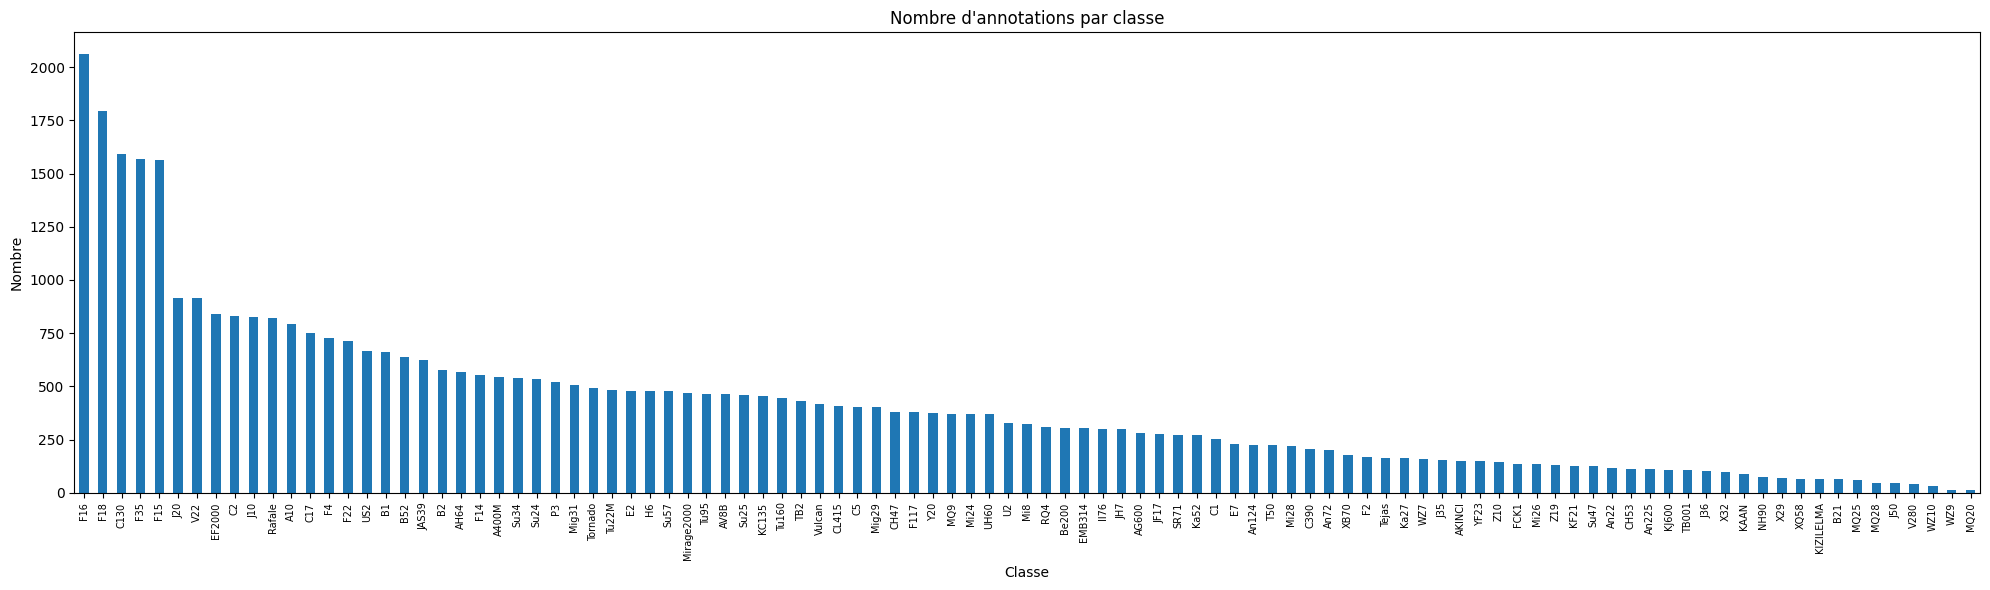

5 classes les moins représentées :
class
J50     46
V280    39
WZ10    32
WZ9     15
MQ20    11
Name: count, dtype: int64

5 classes les plus représentées :
class
F16     2061
F18     1796
C130    1590
F35     1569
F15     1564
Name: count, dtype: int64


In [11]:
#Distribution des classes et déséquilibre du dataset
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 6))
df['class'].value_counts().plot(kind='bar')
plt.title('Nombre d\'annotations par classe')
plt.xlabel('Classe')
plt.ylabel('Nombre')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

# Classes les moins représentées (risque de déséquilibre)
print("5 classes les moins représentées :")
print(df['class'].value_counts().tail())
print("\n5 classes les plus représentées :")
print(df['class'].value_counts().head())

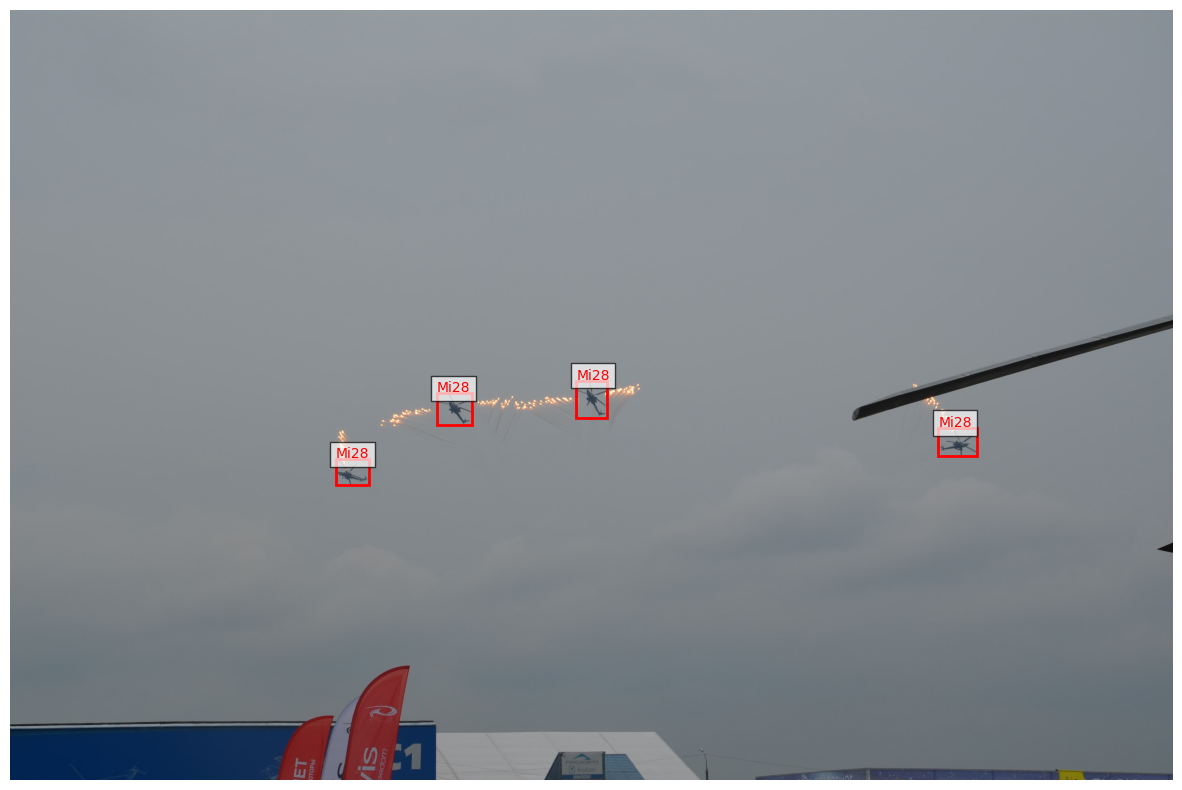

In [12]:
#Visualisation des images avec annotations (bounding boxes)
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

def show_image_with_boxes(filename, df, base_path):
    img_path = f'{base_path}/dataset/{filename}.jpg'
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    fig, ax = plt.subplots(1, figsize=(12, 8))
    ax.imshow(img)
    
    boxes = df[df['filename'] == filename]
    for _, row in boxes.iterrows():
        x, y = row['xmin'], row['ymin']
        w = row['xmax'] - row['xmin']
        h = row['ymax'] - row['ymin']
        rect = patches.Rectangle((x, y), w, h,
                                   linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.text(x, y-5, row['class'], color='red', fontsize=10,
                bbox=dict(facecolor='white', alpha=0.7))
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Tester sur la première image
first_img = df['filename'].iloc[0]
show_image_with_boxes(first_img, df, BASE_PATH)

In [27]:
#Initialisation de l’environnement et chargement du dataset
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'
WORK_PATH = '/kaggle/working'  # Dossier de travail sur Kaggle

df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')
print(f"Dataset chargé : {len(df)} annotations")

Dataset chargé : 41441 annotations


In [28]:
#Filtrage des bounding boxes invalides
before = len(df)

# Supprimer bbox où xmax <= xmin ou ymax <= ymin
df = df[(df['xmax'] > df['xmin']) & (df['ymax'] > df['ymin'])]

# Supprimer bbox hors image
df = df[(df['xmin'] >= 0) & (df['ymin'] >= 0)]
df = df[(df['xmax'] <= df['width']) & (df['ymax'] <= df['height'])]

# Supprimer bbox trop petites (moins de 10px)
df = df[((df['xmax'] - df['xmin']) >= 10) & ((df['ymax'] - df['ymin']) >= 10)]

after = len(df)
print(f"Avant nettoyage : {before}")
print(f"Après nettoyage : {after}")
print(f"Supprimées      : {before - after} bbox invalides")

Avant nettoyage : 41441
Après nettoyage : 41382
Supprimées      : 59 bbox invalides


In [29]:
#Encodage des classes et génération du fichier classes.txt
classes = sorted(df['class'].unique())
class_to_id = {c: i for i, c in enumerate(classes)}
id_to_class = {i: c for c, i in class_to_id.items()}

print(f"Nombre de classes : {len(classes)}")
print(f"Exemple encodage  : F16 → {class_to_id['F16']}, Rafale → {class_to_id['Rafale']}")

# Sauvegarder la liste des classes
with open(f'{WORK_PATH}/classes.txt', 'w') as f:
    f.write('\n'.join(classes))
print("classes.txt sauvegardé !")

Nombre de classes : 101
Exemple encodage  : F16 → 31, Rafale → 69
classes.txt sauvegardé !


In [30]:
# Créer les dossiers train/val/test
for split in ['train', 'val', 'test']:
    os.makedirs(f'{WORK_PATH}/yolo_dataset/{split}/images', exist_ok=True)
    os.makedirs(f'{WORK_PATH}/yolo_dataset/{split}/labels', exist_ok=True)

print("Structure créée :")
for split in ['train', 'val', 'test']:
    print(f"  yolo_dataset/{split}/images/")
    print(f"  yolo_dataset/{split}/labels/")

Structure créée :
  yolo_dataset/train/images/
  yolo_dataset/train/labels/
  yolo_dataset/val/images/
  yolo_dataset/val/labels/
  yolo_dataset/test/images/
  yolo_dataset/test/labels/


In [31]:
# Remplacer 'validation' par 'val' dans le split
df['split'] = df['split'].replace('validation', 'val')

skipped = 0
converted = 0

for filename, group in df.groupby('filename'):
    split = group['split'].iloc[0]
    img_src = f'{BASE_PATH}/dataset/{filename}.jpg'
    
    # Vérifier que l'image existe
    if not os.path.exists(img_src):
        skipped += 1
        continue
    
    # Copier l'image
    img_dst = f'{WORK_PATH}/yolo_dataset/{split}/images/{filename}.jpg'
    shutil.copy(img_src, img_dst)
    
    # Créer le fichier label .txt
    label_path = f'{WORK_PATH}/yolo_dataset/{split}/labels/{filename}.txt'
    with open(label_path, 'w') as f:
        for _, row in group.iterrows():
            cid = class_to_id[row['class']]
            cx = ((row['xmin'] + row['xmax']) / 2) / row['width']
            cy = ((row['ymin'] + row['ymax']) / 2) / row['height']
            bw = (row['xmax'] - row['xmin']) / row['width']
            bh = (row['ymax'] - row['ymin']) / row['height']
            # Clamp entre 0 et 1
            cx  = max(0, min(1, cx))
            cy  = max(0, min(1, cy))
            bw  = max(0, min(1, bw))
            bh  = max(0, min(1, bh))
            f.write(f"{cid} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")
    converted += 1

print(f"Convertis : {converted} images")
print(f"Ignorés   : {skipped} images (introuvables)")

Convertis : 23126 images
Ignorés   : 0 images (introuvables)


In [32]:
#Génération du fichier de configuration YOLO (aircraft.yaml)
yaml_content = f"""path: {WORK_PATH}/yolo_dataset
train: train/images
val: val/images
test: test/images

nc: {len(classes)}
names: {classes}
"""

with open(f'{WORK_PATH}/aircraft.yaml', 'w') as f:
    f.write(yaml_content)

print("aircraft.yaml créé !")
print(yaml_content)

aircraft.yaml créé !
path: /kaggle/working/yolo_dataset
train: train/images
val: val/images
test: test/images

nc: 101
names: ['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22', 'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130', 'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7', 'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2', 'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35', 'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21', 'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28', 'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31', 'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24', 'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas', 'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22', 'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70', 'XQ58', 'Y20', 'YF23', 'Z10', 'Z19']



In [33]:
#Vérification des images et labels par split
for split in ['train', 'val', 'test']:
    n_images = len(os.listdir(f'{WORK_PATH}/yolo_dataset/{split}/images'))
    n_labels = len(os.listdir(f'{WORK_PATH}/yolo_dataset/{split}/labels'))
    print(f"{split:6s} → {n_images} images | {n_labels} labels")

example_label = os.listdir(f'{WORK_PATH}/yolo_dataset/train/labels')[0]
print(f"\nExemple label :")
with open(f'{WORK_PATH}/yolo_dataset/train/labels/{example_label}') as f:
    print(f.read())

train  → 17326 images | 17326 labels
val    → 4256 images | 4256 labels
test   → 1544 images | 1544 labels

Exemple label :
17 0.477927 0.474041 0.955853 0.407738



In [34]:
#Installation et import de YOLOv8
!pip install ultralytics -q
from ultralytics import YOLO
print("YOLOv8 installé !")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 36.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 installé !


In [21]:
# Charger le modèle pré-entraîné YOLOv8 small
model = YOLO('yolov8s.pt')

# Lancer l'entraînement
results = model.train(
    data=f'{WORK_PATH}/aircraft.yaml',
    epochs=50,          # nombre de passages sur le dataset
    imgsz=640,          # taille des images
    batch=16,           # nombre d'images par batch
    patience=10,        # arrêt si pas d'amélioration après 10 epochs
    device=0,           # GPU
    project=f'{WORK_PATH}/runs',
    name='yolov8_aircraft',
    save=True,
    plots=True
)

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/aircraft.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_aircraft, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspe

In [22]:
# Charger le meilleur modèle sauvegardé
best_model = YOLO(f'{WORK_PATH}/runs/yolov8_aircraft/weights/best.pt')

# Évaluer sur le split test
metrics = best_model.val(
    data=f'{WORK_PATH}/aircraft.yaml',
    split='test'
)

print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Précision    : {metrics.box.mp:.4f}")
print(f"Rappel       : {metrics.box.mr:.4f}")

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,164,671 parameters, 0 gradients, 28.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2841.0±870.5 MB/s, size: 388.4 KB)
val: Scanning /kaggle/working/yolo_dataset/test/labels... 1544 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1544/1544 1.5Kit/s 1.0s0.0s
val: New cache created: /kaggle/working/yolo_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 4.9it/s 19.8s0.2ss
                   all       1544       2764      0.686      0.602      0.691      0.617
                   A10         35         62      0.858      0.629      0.788      0.687
                 A400M         32         39      0.788      0.744      0.838      0.775
                 AG600         14         17      0.785      0.765      0.725      0.667
                  AH64         22         40    


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1544 /kaggle/working/yolo_dataset/test/images/f0055552c8a0538a76b175765f443b97.jpg: 448x640 1 F35, 49.1ms
image 2/1544 /kaggle/working/yolo_dataset/test/images/f006aa612a2e0922813d7070136b3445.jpg: 448x640 1 E2, 12.9ms
image 3/1544 /kaggle/working/yolo_dataset/test/images/f007598dacc4b6baa1aae36229c4d594.jpg: 480x640 1 Su57, 46.3ms
image 4/1544 /kaggle/working/yolo_dataset/test/images/f007a9bac628e561239f6ca9f5fa61fc.jpg: 448x640 1 A400M, 13.5ms


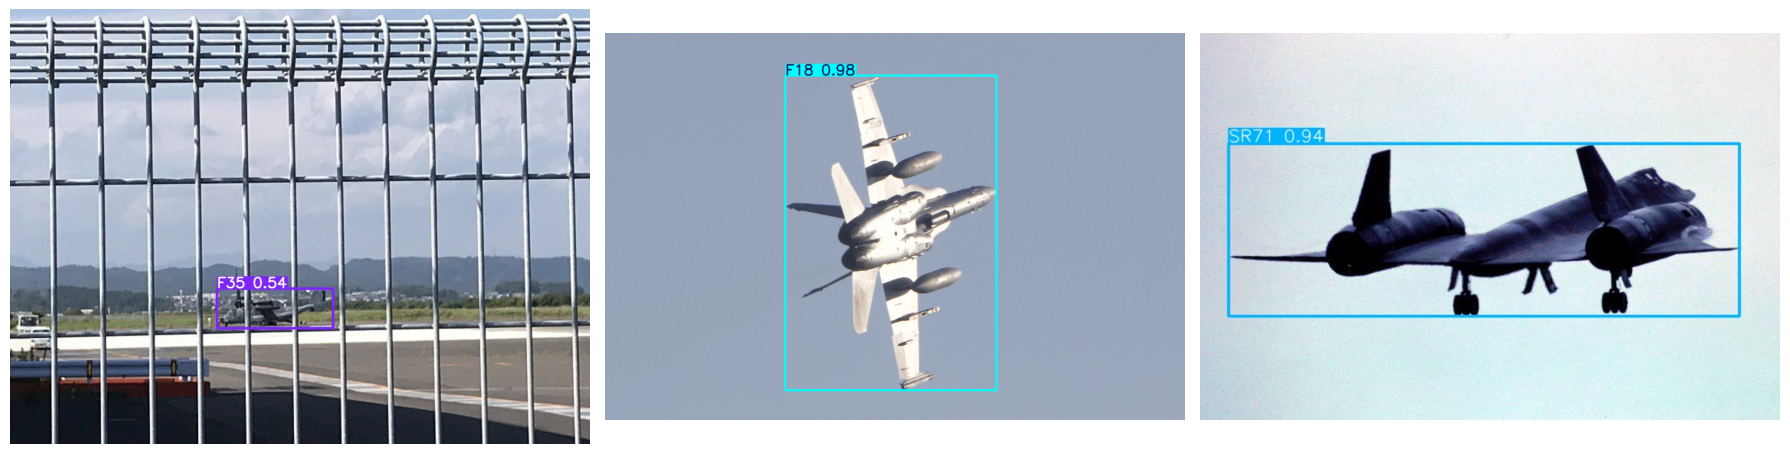

In [23]:
# Tester sur quelques images du split test
test_results = best_model.predict(
    source=f'{WORK_PATH}/yolo_dataset/test/images',
    conf=0.25,
    save=True,
    project=f'{WORK_PATH}/predictions'
)

# Afficher 3 images avec les détections
import glob
pred_images = glob.glob(f'{WORK_PATH}/predictions/**/*.jpg', recursive=True)[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img_path in zip(axes, pred_images):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [39]:
#Vérification de la présence des images et détection des manquantes par split
import os, pandas as pd

BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'
WORK_PATH = '/kaggle/working'

df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')
df['split'] = df['split'].replace('validation', 'val')

for split in ['train', 'val', 'test']:
    img_dir  = f'{WORK_PATH}/yolo_dataset/{split}/images'
    fichiers = set(f.replace('.jpg','') for f in os.listdir(img_dir))
    df_split = df[df['split']==split]
    manquants = df_split[~df_split['filename'].isin(fichiers)]['filename'].nunique()
    print(f'{split} : {len(fichiers)} images présentes | {manquants} manquantes')

train : 17326 images présentes | 14 manquantes
val : 4256 images présentes | 3 manquantes
test : 1544 images présentes | 0 manquantes


In [37]:
#Préparation des DataLoaders pour l’entraînement et la validation
train_frcnn = AircraftDataset(df[df['split']=='train'], f'{WORK_PATH}/yolo_dataset/train/images')
val_frcnn   = AircraftDataset(df[df['split']=='val'],   f'{WORK_PATH}/yolo_dataset/val/images')

train_ld_frcnn = DataLoader(train_frcnn, batch_size=4, shuffle=True,  num_workers=2, collate_fn=collate_fn)
val_ld_frcnn   = DataLoader(val_frcnn,   batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

print(f'Train : {len(train_frcnn):,} | Val : {len(val_frcnn):,}')

Train : 17,340 | Val : 4,259


In [27]:
#Préparation des crops : encodage des classes et création des splits train/val/test
import os
import pandas as pd
from sklearn.preprocessing import LabelEncoder

BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'
CROP_PATH = f'{BASE_PATH}/crop'

df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')
df['split'] = df['split'].replace('validation', 'val')

# Créer un dictionnaire filename → split
filename_to_split = dict(zip(df['filename'], df['split']))

print('Chargement des crops...')
records = []
for class_name in os.listdir(CROP_PATH):
    class_folder = f'{CROP_PATH}/{class_name}'
    if not os.path.isdir(class_folder):
        continue
    for fname in os.listdir(class_folder):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue
        # "5d727c170cf22898_0.jpg" → "5d727c170cf22898"
        stem = os.path.splitext(fname)[0]   # retire .jpg
        stem = '_'.join(stem.split('_')[:-1])  # retire le _0, _1, etc.

        split = filename_to_split.get(stem, None)
        if split is None:
            continue  # ignorer si pas dans le CSV
        records.append({'path': f'{class_folder}/{fname}', 'class': class_name, 'split': split})

crop_df = pd.DataFrame(records)
print(f'Total crops trouves : {len(crop_df):,}')
print(f'Classes             : {crop_df["class"].nunique()}')

le = LabelEncoder()
le.fit(sorted(crop_df['class'].unique()))
NUM_CLS = len(le.classes_)
print(f'Nombre de classes   : {NUM_CLS}')

train_df = crop_df[crop_df['split'] == 'train'].reset_index(drop=True)
val_df   = crop_df[crop_df['split'] == 'val'].reset_index(drop=True)
test_df  = crop_df[crop_df['split'] == 'test'].reset_index(drop=True)

print(f'Train : {len(train_df):,} | Val : {len(val_df):,} | Test : {len(test_df):,}')

Chargement des crops...
Total crops trouves : 41,441
Classes             : 101
Nombre de classes   : 101
Train : 31,127 | Val : 7,545 | Test : 2,769


In [22]:
# entraînement Random Forest pour classification
import time
import numpy as np
import cv2
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, top_k_accuracy_score

IMG_SIZE = (64, 64)

def extract_features(img_path):
    try:
        img = cv2.imread(img_path)
        if img is None:
            return None
        img = cv2.resize(img, IMG_SIZE)
        img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_gray = rgb2gray(img_rgb)

        # HOG (forme)
        hog_f = hog(img_gray, orientations=9,
                    pixels_per_cell=(8,8), cells_per_block=(2,2),
                    feature_vector=True)
        # Histogramme couleur
        hr = np.histogram(img_rgb[:,:,0], bins=16, range=(0,256))[0].astype(float)
        hg = np.histogram(img_rgb[:,:,1], bins=16, range=(0,256))[0].astype(float)
        hb = np.histogram(img_rgb[:,:,2], bins=16, range=(0,256))[0].astype(float)
        col_f = np.concatenate([hr,hg,hb])
        col_f /= (col_f.sum() + 1e-7)
        # Stats texture
        tex_f = np.array([img_gray.mean(), img_gray.std(),
                          np.percentile(img_gray,25), np.percentile(img_gray,75)])
        return np.concatenate([hog_f, col_f, tex_f])
    except:
        return None

print('Extraction des features HOG + couleur + texture...')
X_tr, y_tr, X_te, y_te = [], [], [], []

for subset, X_list, y_list in [(train_df, X_tr, y_tr), (test_df, X_te, y_te)]:
    for _, row in subset.iterrows():
        f = extract_features(row['path'])
        if f is not None:
            X_list.append(f)
            y_list.append(row['class'])

X_tr = np.array(X_tr); X_te = np.array(X_te)
y_tr_enc = le.transform(y_tr); y_te_enc = le.transform(y_te)
print(f'Train : {X_tr.shape} | Test : {X_te.shape} | Dim features : {X_tr.shape[1]}')

# ── Entraînement Random Forest ────────────────────────────────────
print()
print('=' * 50)
print('ENTRAINEMENT : Random Forest (200 arbres)')
print('=' * 50)

start_rf = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=None,
    min_samples_split=5, min_samples_leaf=2,
    max_features='sqrt', n_jobs=-1, random_state=42, verbose=1
)
rf_model.fit(X_tr, y_tr_enc)
rf_train_time = time.time() - start_rf

# Evaluation
start_inf = time.time()
y_pred_rf   = rf_model.predict(X_te)
y_proba_rf  = rf_model.predict_proba(X_te)
rf_inf_time = time.time() - start_inf

rf_acc  = accuracy_score(y_te_enc, y_pred_rf)
rf_top5 = top_k_accuracy_score(y_te_enc, y_proba_rf, k=min(5, NUM_CLS), labels=list(range(NUM_CLS)))
rf_fps  = len(X_te) / (rf_inf_time + 1e-9)

print(f'\n  Accuracy Top-1 : {rf_acc:.4f} ({rf_acc*100:.2f}%)')
print(f'  Accuracy Top-5 : {rf_top5:.4f} ({rf_top5*100:.2f}%)')
print(f'  FPS            : {rf_fps:.1f}')
print(f'  Temps train    : {rf_train_time:.1f}s')

Extraction des features HOG + couleur + texture...
Train : (31127, 1816) | Test : (2769, 1816) | Dim features : 1816

ENTRAINEMENT : Random Forest (200 arbres)


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:  8.9min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  9.3min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s



  Accuracy Top-1 : 0.1629 (16.29%)
  Accuracy Top-5 : 0.3615 (36.15%)
  FPS            : 6837.4
  Temps train    : 556.7s


[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.2s finished


TEST RANDOM FOREST sur quelques exemples


[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      |

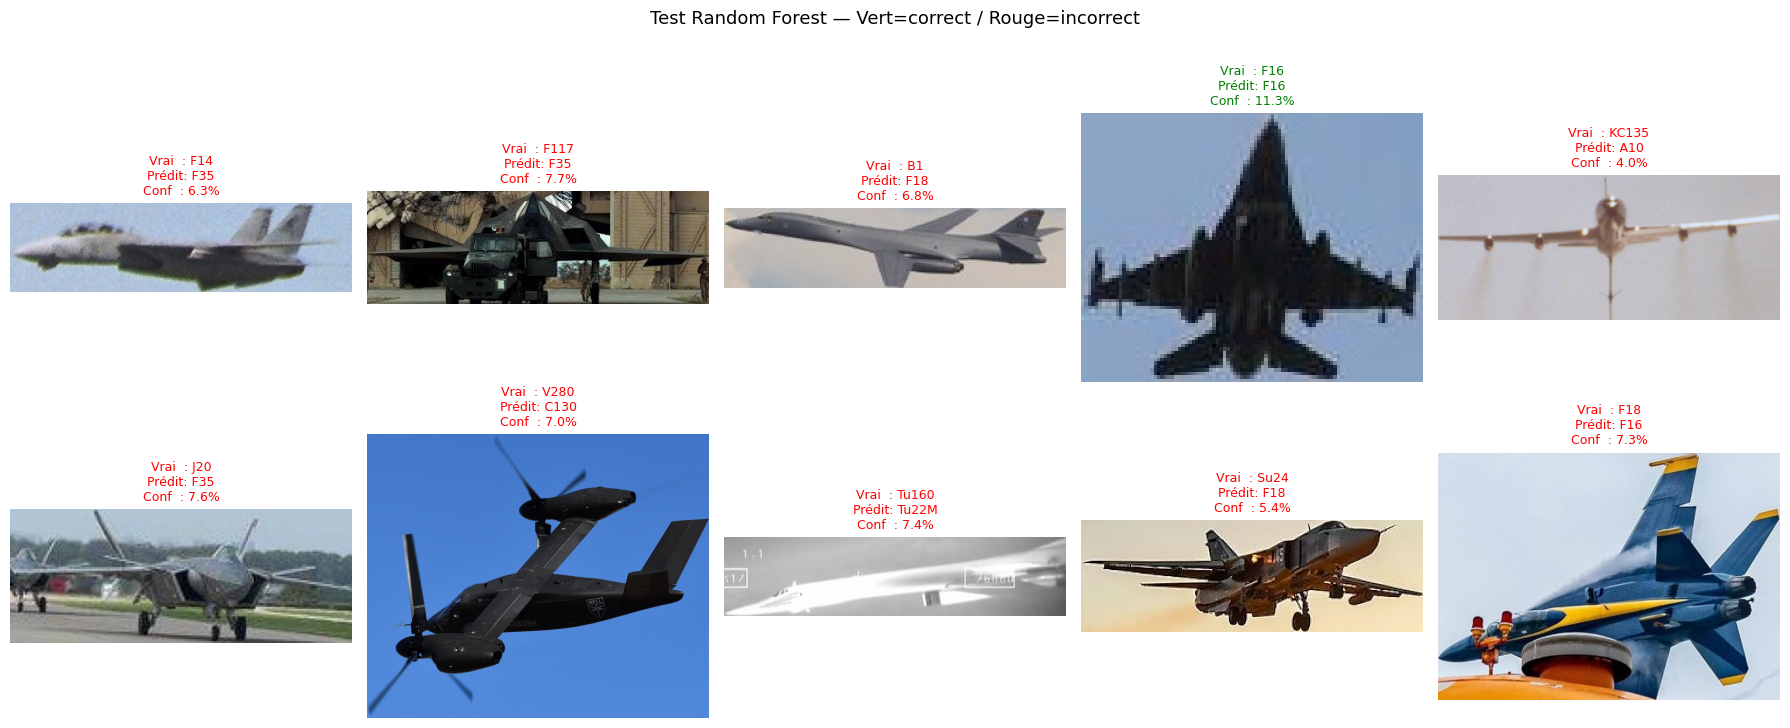


Top-5 prédictions pour le premier exemple :
  1. F35             : 6.30%
  2. F18             : 5.15%
  3. J20             : 4.33%
  4. F15             : 3.87%
  5. V22             : 3.36%

Vraie classe : F14


[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.0s finished


In [31]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ── Prédictions sur quelques images de test ──────────────────────
print('TEST RANDOM FOREST sur quelques exemples')
print('=' * 50)

# Prendre 10 exemples aléatoires du test
sample = test_df.sample(10, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, (_, row) in enumerate(sample.iterrows()):
    # Extraire features et prédire
    feats = extract_features(row['path'])
    if feats is None:
        continue
    pred_enc  = rf_model.predict([feats])[0]
    proba     = rf_model.predict_proba([feats])[0]
    pred_cls  = le.inverse_transform([pred_enc])[0]
    true_cls  = row['class']
    confidence = proba.max() * 100

    # Afficher l'image
    img = cv2.imread(row['path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].axis('off')

    color = 'green' if pred_cls == true_cls else 'red'
    axes[i].set_title(
        f'Vrai  : {true_cls}\nPrédit: {pred_cls}\nConf  : {confidence:.1f}%',
        fontsize=9, color=color
    )

plt.suptitle('Test Random Forest — Vert=correct / Rouge=incorrect', fontsize=13)
plt.tight_layout()
plt.savefig(f'{WORK_PATH}/test_rf.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Top 5 prédictions pour 1 exemple ────────────────────────────
print('\nTop-5 prédictions pour le premier exemple :')
feats = extract_features(sample.iloc[0]['path'])
proba = rf_model.predict_proba([feats])[0]
top5_idx = np.argsort(proba)[::-1][:5]
for rank, idx in enumerate(top5_idx, 1):
    print(f'  {rank}. {le.inverse_transform([idx])[0]:<15} : {proba[idx]*100:.2f}%')
print(f'\nVraie classe : {sample.iloc[0]["class"]}')

In [48]:
#Entraînement EfficientNetV2 pour classification

import time
import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_PATH  = '/kaggle/working'
IMG_SIZE   = 224
BATCH_SIZE = 64
EPOCHS     = 20
PATIENCE   = 7

print(f'Device : {DEVICE} | Classes : {NUM_CLS}')

# Transforms — EfficientNetV2 bénéficie d'augmentations plus fortes
train_tfm = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(p=0.1),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
test_tfm = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class CropDataset(Dataset):
    def __init__(self, df_sub, transform):
        self.data = df_sub.reset_index(drop=True)
        self.tfm  = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        lbl = int(le.transform([row['class']])[0])
        return self.tfm(img), lbl

train_ld_eff = DataLoader(CropDataset(train_df, train_tfm),
                           batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_ld_eff   = DataLoader(CropDataset(val_df,   test_tfm),
                           batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_ld_eff  = DataLoader(CropDataset(test_df,  test_tfm),
                           batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ── EfficientNetV2-S pré-entraîné ────────────────────────────
eff = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)

# Dégeler les 30 dernières couches
for p in list(eff.parameters())[:-30]:
    p.requires_grad = False

# Remplacer la tête de classification
in_features = eff.classifier[1].in_features
eff.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLS)
)
eff = eff.to(DEVICE)

# Optimiseur + scheduler
opt_eff   = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, eff.parameters()),
    lr=1e-4, weight_decay=1e-3
)
sched_eff = torch.optim.lr_scheduler.CosineAnnealingLR(opt_eff, T_max=EPOCHS)
crit_eff  = nn.CrossEntropyLoss(label_smoothing=0.1)  # label smoothing pour 101 classes

best_val_eff = 0.0
eff_hist     = {'train_acc':[], 'val_acc':[], 'loss':[]}
no_improve   = 0
start_eff    = time.time()

print()
print('=' * 55)
print('ENTRAINEMENT : EfficientNetV2-S')
print('=' * 55)

for epoch in range(1, EPOCHS+1):
    eff.train()
    tot_loss = correct = total = 0
    for imgs, lbls in train_ld_eff:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        opt_eff.zero_grad()
        out  = eff(imgs)
        loss = crit_eff(out, lbls)
        loss.backward()
        opt_eff.step()
        tot_loss += loss.item() * imgs.size(0)
        correct  += out.argmax(1).eq(lbls).sum().item()
        total    += imgs.size(0)
    tr_acc  = correct / total
    tr_loss = tot_loss / total

    eff.eval()
    vc = vt = 0
    with torch.no_grad():
        for imgs, lbls in val_ld_eff:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            vc += eff(imgs).argmax(1).eq(lbls).sum().item()
            vt += imgs.size(0)
    val_acc = vc / vt
    sched_eff.step()

    eff_hist['train_acc'].append(tr_acc)
    eff_hist['val_acc'].append(val_acc)
    eff_hist['loss'].append(tr_loss)

    if val_acc > best_val_eff:
        best_val_eff = val_acc
        no_improve   = 0
        torch.save(eff.state_dict(), f'{WORK_PATH}/best_eff.pth')
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f'Early stopping a l\'epoch {epoch}')
            break

    print(f'Epoch {epoch:2d}/{EPOCHS} | Loss: {tr_loss:.4f} | '
          f'Train: {tr_acc*100:.2f}% | Val: {val_acc*100:.2f}%'
          + (' BEST' if val_acc == best_val_eff else ''))

eff_train_time = time.time() - start_eff
print(f'\nTemps : {eff_train_time/60:.1f} min')
print(f'Meilleure val : {best_val_eff*100:.2f}%')

Device : cuda | Classes : 101

ENTRAINEMENT : EfficientNetV2-S
Epoch  1/20 | Loss: 4.1795 | Train: 8.78% | Val: 15.32% BEST
Epoch  2/20 | Loss: 3.6442 | Train: 18.90% | Val: 25.01% BEST
Epoch  3/20 | Loss: 3.3651 | Train: 25.24% | Val: 32.13% BEST
Epoch  4/20 | Loss: 3.1970 | Train: 29.66% | Val: 36.05% BEST
Epoch  5/20 | Loss: 3.0802 | Train: 32.23% | Val: 38.50% BEST
Epoch  6/20 | Loss: 2.9971 | Train: 34.78% | Val: 40.57% BEST
Epoch  7/20 | Loss: 2.9230 | Train: 36.34% | Val: 42.43% BEST
Epoch  8/20 | Loss: 2.8646 | Train: 38.55% | Val: 43.74% BEST
Epoch  9/20 | Loss: 2.8159 | Train: 39.68% | Val: 45.84% BEST
Epoch 10/20 | Loss: 2.7672 | Train: 41.17% | Val: 46.93% BEST
Epoch 11/20 | Loss: 2.7348 | Train: 42.19% | Val: 47.36% BEST
Epoch 12/20 | Loss: 2.7036 | Train: 43.02% | Val: 47.42% BEST
Epoch 13/20 | Loss: 2.6775 | Train: 43.88% | Val: 48.72% BEST
Epoch 14/20 | Loss: 2.6665 | Train: 44.27% | Val: 48.99% BEST
Epoch 15/20 | Loss: 2.6460 | Train: 44.64% | Val: 49.45% BEST
Epoch 16

RESULTATS : EfficientNetV2-S sur Test
  Accuracy Top-1 : 0.5096  (50.96%)
  Accuracy Top-5 : 0.7970 (79.70%)
  FPS            : 172.2


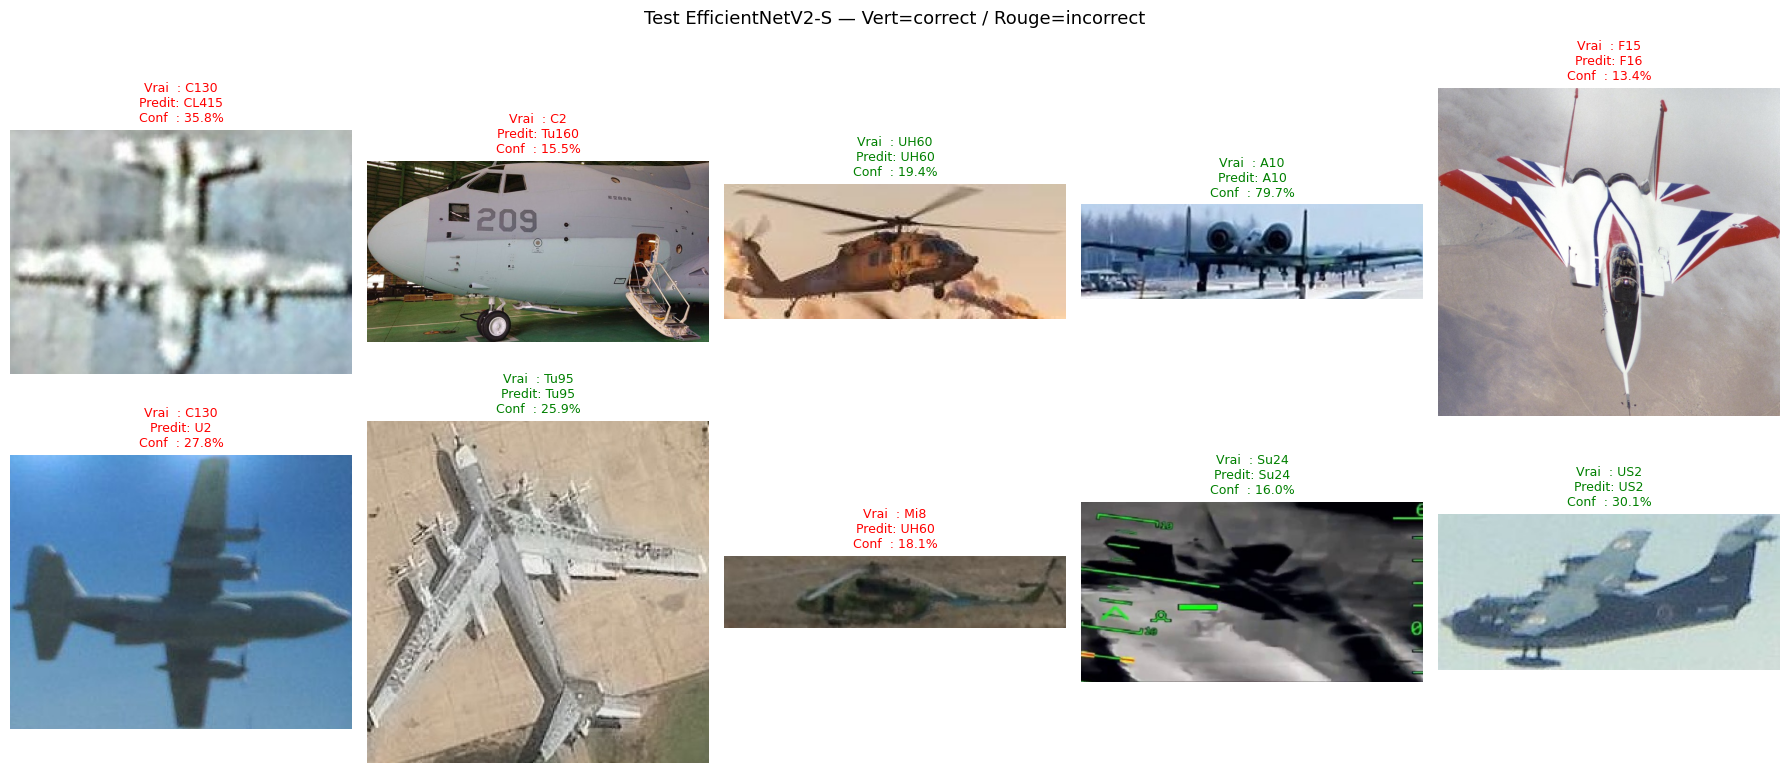


  COMPARAISON FINALE — 3 MODELES DE CLASSIFICATION
Modele                  Top-1    Top-5      FPS
------------------------------------------------------------
CNN (ResNet50)         70.49%   89.27%    122.6
Random Forest          16.29%   36.15%   6837.4
EfficientNetV2-S       50.96%   79.70%    172.2

Meilleur modele : CNN ResNet50 (70.49%)


In [49]:
#Test EfficientNetV2
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, top_k_accuracy_score
from PIL import Image
import torchvision.transforms as T
import time

DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_PATH = '/kaggle/working'

# Recharger le modèle
eff_eval = models.efficientnet_v2_s(weights=None)
in_features = eff_eval.classifier[1].in_features
eff_eval.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLS)
)
eff_eval.load_state_dict(torch.load(f'{WORK_PATH}/best_eff.pth'))
eff_eval = eff_eval.to(DEVICE)
eff_eval.eval()

# ── Évaluation sur le jeu de test ────────────────────────────
all_preds_eff, all_labels_eff, all_probs_eff = [], [], []
start_inf = time.time()

with torch.no_grad():
    for imgs, lbls in test_ld_eff:
        imgs = imgs.to(DEVICE)
        out  = eff_eval(imgs)
        prob = torch.softmax(out, dim=1).cpu().numpy()
        all_preds_eff.extend(out.argmax(1).cpu().numpy())
        all_labels_eff.extend(lbls.numpy())
        all_probs_eff.extend(prob)

eff_inf_time  = time.time() - start_inf
all_probs_eff = np.array(all_probs_eff)

eff_acc  = accuracy_score(all_labels_eff, all_preds_eff)
eff_top5 = top_k_accuracy_score(all_labels_eff, all_probs_eff,
                                  k=min(5, NUM_CLS), labels=list(range(NUM_CLS)))
eff_fps  = len(test_df) / (eff_inf_time + 1e-9)

print('=' * 50)
print('RESULTATS : EfficientNetV2-S sur Test')
print('=' * 50)
print(f'  Accuracy Top-1 : {eff_acc:.4f}  ({eff_acc*100:.2f}%)')
print(f'  Accuracy Top-5 : {eff_top5:.4f} ({eff_top5*100:.2f}%)')
print(f'  FPS            : {eff_fps:.1f}')

# ── Visualisation 10 exemples ─────────────────────────────────
test_tfm_vis = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

sample = test_df.sample(10, random_state=7).reset_index(drop=True)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

eff_eval.eval()
with torch.no_grad():
    for i, (_, row) in enumerate(sample.iterrows()):
        img_pil = Image.open(row['path']).convert('RGB')
        tensor  = test_tfm_vis(img_pil).unsqueeze(0).to(DEVICE)
        out     = eff_eval(tensor)
        probs   = torch.softmax(out, dim=1).cpu().numpy()[0]
        pred_cls= le.inverse_transform([probs.argmax()])[0]
        true_cls= row['class']
        conf    = probs.max() * 100

        axes[i].imshow(img_pil)
        axes[i].axis('off')
        color = 'green' if pred_cls == true_cls else 'red'
        axes[i].set_title(
            f'Vrai  : {true_cls}\nPredit: {pred_cls}\nConf  : {conf:.1f}%',
            fontsize=9, color=color
        )

plt.suptitle('Test EfficientNetV2-S — Vert=correct / Rouge=incorrect', fontsize=13)
plt.tight_layout()
plt.savefig(f'{WORK_PATH}/test_efficientnet.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Comparaison finale 3 modèles ──────────────────────────────
print()
print('=' * 60)
print('  COMPARAISON FINALE — 3 MODELES DE CLASSIFICATION')
print('=' * 60)
print(f'{"Modele":<20} {"Top-1":>8} {"Top-5":>8} {"FPS":>8}')
print('-' * 60)
print(f'{"CNN (ResNet50)":<20} {cnn_acc*100:>7.2f}% {cnn_top5*100:>7.2f}% {cnn_fps:>8.1f}')
print(f'{"Random Forest":<20} {rf_acc*100:>7.2f}% {rf_top5*100:>7.2f}% {rf_fps:>8.1f}')
print(f'{"EfficientNetV2-S":<20} {eff_acc*100:>7.2f}% {eff_top5*100:>7.2f}% {eff_fps:>8.1f}')
print('=' * 60)

winner = max([('CNN ResNet50', cnn_acc), ('Random Forest', rf_acc),
              ('EfficientNetV2', eff_acc)], key=lambda x: x[1])
print(f'\nMeilleur modele : {winner[0]} ({winner[1]*100:.2f}%)')

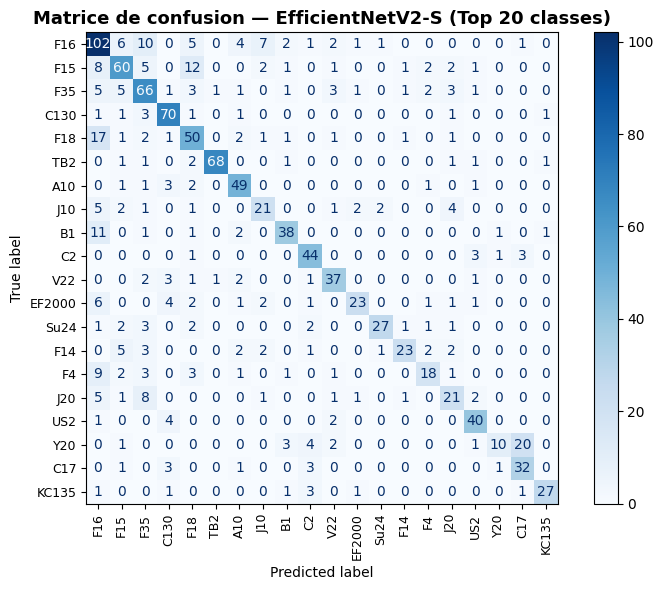


Accuracy par classe (Top 20) :
-----------------------------------
F16               71.8%  ██████████████
F15               63.2%  ████████████
F35               70.2%  ██████████████
C130              88.6%  █████████████████
F18               64.1%  ████████████
TB2               89.5%  █████████████████
A10               84.5%  ████████████████
J10               53.8%  ██████████
B1                69.1%  █████████████
C2                84.6%  ████████████████
V22               77.1%  ███████████████
EF2000            54.8%  ██████████
Su24              67.5%  █████████████
F14               56.1%  ███████████
F4                46.2%  █████████
J20               51.2%  ██████████
US2               85.1%  █████████████████
Y20               24.4%  ████
C17               78.0%  ███████████████
KC135             77.1%  ███████████████


In [53]:
#matrice de confusion EfficientNetV2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd

# Top 20 classes les plus fréquentes dans le test
top20 = list(test_df['class'].value_counts().head(20).index)
top20_idx = le.transform(top20)

# Filtrer les prédictions
mask = np.isin(all_labels_eff, top20_idx)
y_true = np.array(all_labels_eff)[mask]
y_pred = np.array(all_preds_eff)[mask]

# Garder seulement les classes présentes
used  = [l for l in top20_idx if l in np.unique(y_true)]
names = le.inverse_transform(used)

cm   = confusion_matrix(y_true, y_pred, labels=used)
disp = ConfusionMatrixDisplay(cm, display_labels=names)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=90, colorbar=True)
ax.set_title('Matrice de confusion — EfficientNetV2-S (Top 20 classes)',
             fontsize=13, fontweight='bold')
ax.tick_params(labelsize=9)

plt.tight_layout()
plt.savefig(f'{WORK_PATH}/confusion_efficientnet.png', dpi=120, bbox_inches='tight')
plt.show()

# Accuracy par classe
print('\nAccuracy par classe (Top 20) :')
print('-' * 35)
for i, (idx, name) in enumerate(zip(used, names)):
    row_sum = cm[i].sum()
    acc     = cm[i][i] / row_sum if row_sum > 0 else 0
    bar     = '█' * int(acc * 20)
    print(f'{name:<15} {acc*100:>6.1f}%  {bar}')

In [12]:
#entrainement CNN pour classification
import time
import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import accuracy_score, top_k_accuracy_score
import numpy as np

DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG_CNN    = 224
BATCH_SIZE = 64
CNN_EPOCHS = 20
print(f'Device : {DEVICE} | Classes : {NUM_CLS}')

# Dataset
class CropDataset(Dataset):
    def __init__(self, df_sub, transform):
        self.data = df_sub.reset_index(drop=True)
        self.tfm  = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        lbl = int(le.transform([row['class']])[0])
        return self.tfm(img), lbl

train_tfm = T.Compose([
    T.Resize((IMG_CNN, IMG_CNN)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
test_tfm = T.Compose([
    T.Resize((IMG_CNN, IMG_CNN)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train_ld = DataLoader(CropDataset(train_df, train_tfm), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_ld   = DataLoader(CropDataset(val_df,   test_tfm),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_ld  = DataLoader(CropDataset(test_df,  test_tfm),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Modele ResNet50
cnn = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
for p in list(cnn.parameters())[:-20]:
    p.requires_grad = False
cnn.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(cnn.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLS)
)
cnn = cnn.to(DEVICE)

opt   = torch.optim.Adam(filter(lambda p: p.requires_grad, cnn.parameters()), lr=1e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CNN_EPOCHS)
crit  = nn.CrossEntropyLoss()

best_val = 0.0
cnn_hist = {'train_acc':[], 'val_acc':[], 'loss':[]}
start_cnn = time.time()

print()
print('=' * 50)
print('ENTRAINEMENT : CNN ResNet50')
print('=' * 50)

for epoch in range(1, CNN_EPOCHS+1):
    cnn.train()
    tot_loss = correct = total = 0
    for imgs, lbls in train_ld:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        opt.zero_grad()
        out  = cnn(imgs)
        loss = crit(out, lbls)
        loss.backward(); opt.step()
        tot_loss += loss.item() * imgs.size(0)
        correct  += out.argmax(1).eq(lbls).sum().item()
        total    += imgs.size(0)
    tr_acc = correct / total
    tr_loss = tot_loss / total

    cnn.eval()
    vc = vt = 0
    with torch.no_grad():
        for imgs, lbls in val_ld:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            vc += cnn(imgs).argmax(1).eq(lbls).sum().item()
            vt += imgs.size(0)
    val_acc = vc / vt
    sched.step()
    cnn_hist['train_acc'].append(tr_acc)
    cnn_hist['val_acc'].append(val_acc)
    cnn_hist['loss'].append(tr_loss)
    if val_acc > best_val:
        best_val = val_acc
        torch.save(cnn.state_dict(), f'{WORK_PATH}/best_cnn.pth')
    print(f'Epoch {epoch:2d}/{CNN_EPOCHS} | Loss: {tr_loss:.4f} | '
          f'Train: {tr_acc*100:.2f}% | Val: {val_acc*100:.2f}%'
          + (' BEST' if val_acc == best_val else ''))

cnn_train_time = time.time() - start_cnn
print(f'\nTemps entrainement CNN : {cnn_train_time/60:.1f} min')
print(f'Meilleure val accuracy : {best_val*100:.2f}%')

Device : cuda | Classes : 101
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 145MB/s]



ENTRAINEMENT : CNN ResNet50
Epoch  1/20 | Loss: 3.4879 | Train: 19.37% | Val: 33.65% BEST
Epoch  2/20 | Loss: 2.3381 | Train: 41.10% | Val: 43.45% BEST
Epoch  3/20 | Loss: 1.8191 | Train: 52.83% | Val: 53.06% BEST
Epoch  4/20 | Loss: 1.4783 | Train: 60.99% | Val: 55.60% BEST
Epoch  5/20 | Loss: 1.2329 | Train: 67.16% | Val: 60.34% BEST
Epoch  6/20 | Loss: 1.0488 | Train: 71.96% | Val: 61.54% BEST
Epoch  7/20 | Loss: 0.9115 | Train: 75.11% | Val: 63.06% BEST
Epoch  8/20 | Loss: 0.7806 | Train: 78.81% | Val: 64.21% BEST
Epoch  9/20 | Loss: 0.6808 | Train: 81.27% | Val: 65.46% BEST
Epoch 10/20 | Loss: 0.5889 | Train: 83.51% | Val: 66.56% BEST
Epoch 11/20 | Loss: 0.5190 | Train: 85.56% | Val: 67.04% BEST
Epoch 12/20 | Loss: 0.4520 | Train: 87.41% | Val: 68.11% BEST
Epoch 13/20 | Loss: 0.4024 | Train: 88.67% | Val: 67.38%
Epoch 14/20 | Loss: 0.3558 | Train: 89.93% | Val: 67.93%
Epoch 15/20 | Loss: 0.3216 | Train: 91.04% | Val: 68.63% BEST
Epoch 16/20 | Loss: 0.2965 | Train: 91.63% | Val: 6

In [2]:

import os, pandas as pd
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'
WORK_PATH = '/kaggle/working'

# Recharger crop_df et splits
df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')
df['split'] = df['split'].replace('validation', 'val')
filename_to_split = dict(zip(df['filename'], df['split']))

CROP_PATH = f'{BASE_PATH}/crop'
records = []
for class_name in os.listdir(CROP_PATH):
    class_folder = f'{CROP_PATH}/{class_name}'
    if not os.path.isdir(class_folder): continue
    for fname in os.listdir(class_folder):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')): continue
        stem  = '_'.join(os.path.splitext(fname)[0].split('_')[:-1])
        split = filename_to_split.get(stem, None)
        if split is None: continue
        records.append({'path': f'{class_folder}/{fname}', 'class': class_name, 'split': split})

crop_df  = pd.DataFrame(records)
le       = LabelEncoder()
le.fit(sorted(crop_df['class'].unique()))
NUM_CLS  = len(le.classes_)
test_df  = crop_df[crop_df['split'] == 'test'].reset_index(drop=True)
val_df   = crop_df[crop_df['split'] == 'val'].reset_index(drop=True)

# Recréer test_ld
class CropDataset(Dataset):
    def __init__(self, df_sub, transform):
        self.data = df_sub.reset_index(drop=True)
        self.tfm  = transform
    def __len__(self): return len(self.data)
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        return self.tfm(img), int(le.transform([row['class']])[0])

test_tfm = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
test_ld = DataLoader(CropDataset(test_df, test_tfm), batch_size=64, shuffle=False, num_workers=2)
print(f'Pret : {NUM_CLS} classes | {len(test_df):,} images de test')

Pret : 101 classes | 2,769 images de test


In [13]:
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import time
from sklearn.metrics import accuracy_score, top_k_accuracy_score

WORK_PATH = '/kaggle/working'
DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Recréer l'architecture
cnn = models.resnet50(weights=None)
cnn.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(cnn.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLS)
)
cnn.load_state_dict(torch.load(f'{WORK_PATH}/best_cnn.pth'))
cnn = cnn.to(DEVICE)
cnn.eval()

all_preds, all_labels, all_probs = [], [], []
start_inf = time.time()

with torch.no_grad():
    for imgs, lbls in test_ld:
        imgs = imgs.to(DEVICE)
        out  = cnn(imgs)
        prob = torch.softmax(out, dim=1).cpu().numpy()
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(lbls.numpy())
        all_probs.extend(prob)

cnn_inf_time = time.time() - start_inf
all_probs    = np.array(all_probs)

cnn_acc  = accuracy_score(all_labels, all_preds)
cnn_top5 = top_k_accuracy_score(all_labels, all_probs, k=min(5, NUM_CLS), labels=list(range(NUM_CLS)))
cnn_fps  = len(test_df) / (cnn_inf_time + 1e-9)

print(f'  Accuracy Top-1 : {cnn_acc:.4f} ({cnn_acc*100:.2f}%)')
print(f'  Accuracy Top-5 : {cnn_top5:.4f} ({cnn_top5*100:.2f}%)')
print(f'  FPS            : {cnn_fps:.1f}')

  Accuracy Top-1 : 0.7049 (70.49%)
  Accuracy Top-5 : 0.8927 (89.27%)
  FPS            : 122.6


TEST CNN sur quelques exemples


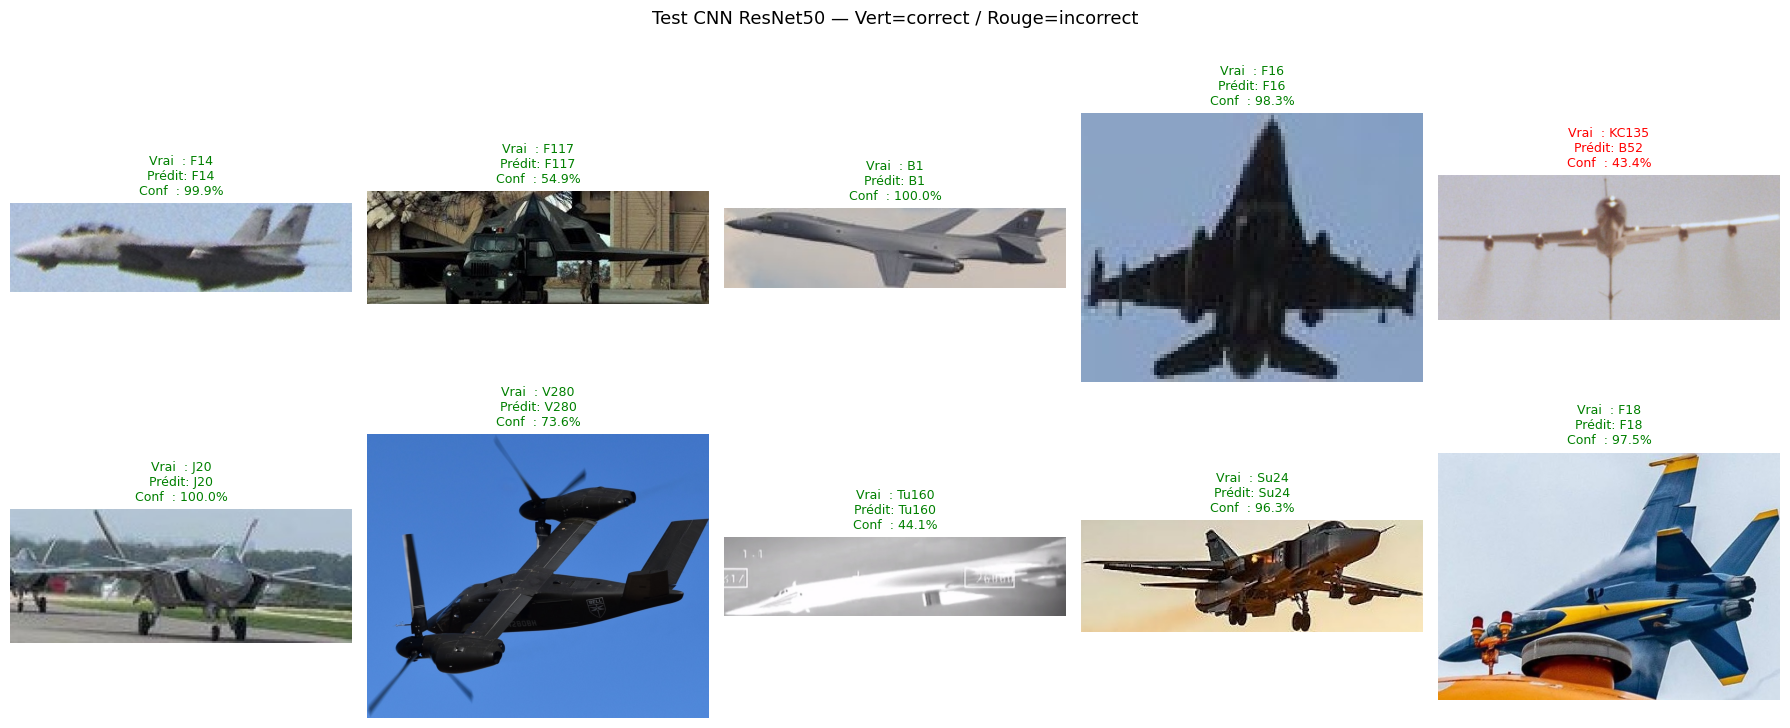


Top-5 predictions pour le premier exemple :
  1. F14             : 99.87%
  2. F4              : 0.02%
  3. Mig29           : 0.02%
  4. Tornado         : 0.02%
  5. Mig31           : 0.01%

Vraie classe : F14


In [14]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as T
import torch

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('TEST CNN sur quelques exemples')
print('=' * 50)

# Prendre 10 exemples aléatoires du test
sample = test_df.sample(10, random_state=42).reset_index(drop=True)

test_tfm = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

cnn.eval()
with torch.no_grad():
    for i, (_, row) in enumerate(sample.iterrows()):
        # Charger et transformer l'image
        img_pil = Image.open(row['path']).convert('RGB')
        tensor  = test_tfm(img_pil).unsqueeze(0).to(DEVICE)

        # Prédiction
        out      = cnn(tensor)
        probs    = torch.softmax(out, dim=1).cpu().numpy()[0]
        pred_idx = probs.argmax()
        pred_cls = le.inverse_transform([pred_idx])[0]
        true_cls = row['class']
        conf     = probs.max() * 100

        # Afficher
        axes[i].imshow(img_pil)
        axes[i].axis('off')
        color = 'green' if pred_cls == true_cls else 'red'
        axes[i].set_title(
            f'Vrai  : {true_cls}\nPrédit: {pred_cls}\nConf  : {conf:.1f}%',
            fontsize=9, color=color
        )

plt.suptitle('Test CNN ResNet50 — Vert=correct / Rouge=incorrect', fontsize=13)
plt.tight_layout()
plt.savefig(f'{WORK_PATH}/test_cnn.png', dpi=120, bbox_inches='tight')
plt.show()

# Top-5 pour 1 exemple
print('\nTop-5 predictions pour le premier exemple :')
img_pil = Image.open(sample.iloc[0]['path']).convert('RGB')
tensor  = test_tfm(img_pil).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    probs = torch.softmax(cnn(tensor), dim=1).cpu().numpy()[0]
top5_idx = np.argsort(probs)[::-1][:5]
for rank, idx in enumerate(top5_idx, 1):
    print(f'  {rank}. {le.inverse_transform([idx])[0]:<15} : {probs[idx]*100:.2f}%')
print(f'\nVraie classe : {sample.iloc[0]["class"]}')

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.2s finished


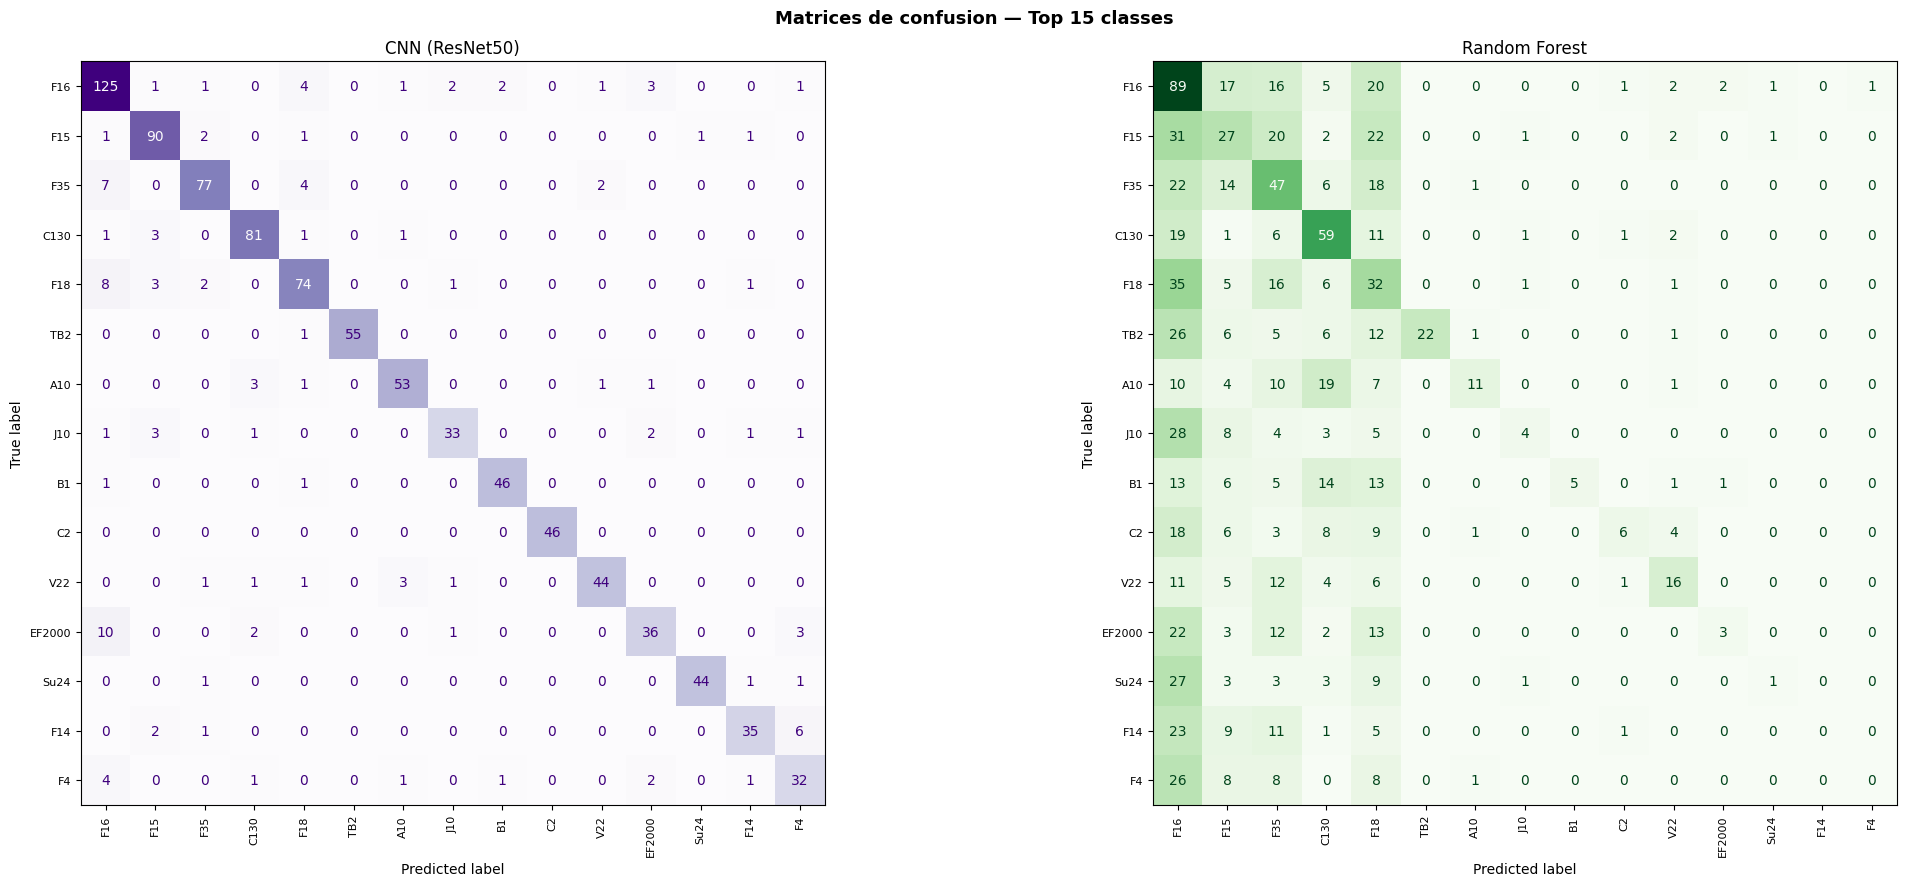

In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ── Matrice de confusion Top 15 classes ──────────────────────────
top15 = list(test_df['class'].value_counts().head(15).index)
top15_idx = le.transform(top15)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
fig.suptitle('Matrices de confusion — Top 15 classes', fontsize=13, fontweight='bold')
y_te_enc  = le.transform(test_df['class'].tolist())
y_pred_rf = rf_model.predict(X_te)
for ax, y_true, y_pred, title, cmap in [
    (axes[0], np.array(all_labels), np.array(all_preds), 'CNN (ResNet50)', 'Purples'),
    (axes[1], y_te_enc,             y_pred_rf,            'Random Forest',  'Greens'),
]:
    mask  = np.isin(y_true, top15_idx)
    ytr   = y_true[mask]
    ypr   = y_pred[mask]
    used  = [l for l in top15_idx if l in np.unique(ytr)]
    names = le.inverse_transform(used)
    cm    = confusion_matrix(ytr, ypr, labels=used)
    disp  = ConfusionMatrixDisplay(cm, display_labels=names)
    disp.plot(ax=ax, cmap=cmap, xticks_rotation=90, colorbar=False)
    ax.set_title(title, fontsize=12)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig(f'{WORK_PATH}/confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()


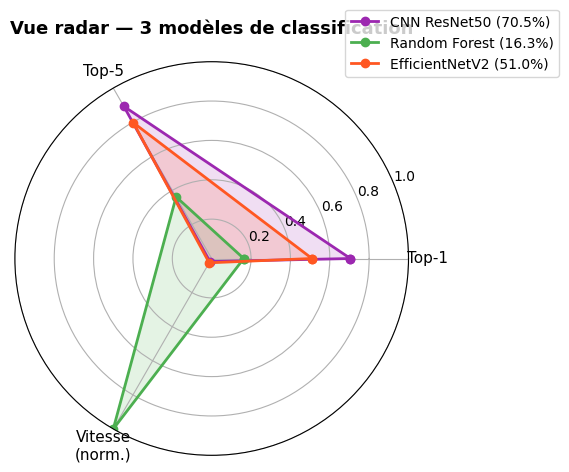

In [56]:
import numpy as np
import matplotlib.pyplot as plt

WORK_PATH = '/kaggle/working'

fig = plt.figure(figsize=(6, 6))
ax  = fig.add_subplot(111, polar=True)

cats   = ['Top-1', 'Top-5', 'Vitesse\n(norm.)']
N      = len(cats)
angles = [n/float(N)*2*np.pi for n in range(N)] + [0]

max_fps = max(cnn_fps, rf_fps, eff_fps)

v_cnn = [cnn_acc, cnn_top5, cnn_fps/max_fps] + [cnn_acc]
v_rf  = [rf_acc,  rf_top5,  rf_fps/max_fps]  + [rf_acc]
v_eff = [eff_acc, eff_top5, eff_fps/max_fps] + [eff_acc]

ax.plot(angles, v_cnn, 'o-', lw=2, color='#9C27B0', label=f'CNN ResNet50 ({cnn_acc*100:.1f}%)')
ax.fill(angles, v_cnn, alpha=0.15, color='#9C27B0')

ax.plot(angles, v_rf,  'o-', lw=2, color='#4CAF50', label=f'Random Forest ({rf_acc*100:.1f}%)')
ax.fill(angles, v_rf,  alpha=0.15, color='#4CAF50')

ax.plot(angles, v_eff, 'o-', lw=2, color='#FF5722', label=f'EfficientNetV2 ({eff_acc*100:.1f}%)')
ax.fill(angles, v_eff, alpha=0.15, color='#FF5722')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(cats, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Vue radar — 3 modèles de classification', pad=20, fontsize=13, fontweight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=10)

plt.tight_layout()
plt.savefig(f'{WORK_PATH}/radar_3modeles.png', dpi=150, bbox_inches='tight')
plt.show()